<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Simulations validating the Rayleigh-based isotropic diffusion test against other movement models.
> - **Manuscript panels:** ED Fig. 5C-E
> - **Inputs:** None (simulated with `troutpy_reproducibility.diffusion_simulation`)
> - **Outputs:** Heatmaps and example simulations
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

In this notebook we aim to assess the performance  our raigheigh distribution-based model to capture patterns matching isotropic diffusion. For this, we will simulated datasets presenting different either diffusion (2D or 3D) or any other type of transcript distribution and see if the model identified their distribution as different from raileigh. 

## Import packages

We specifically have all functions needed for this task in diffusion_simulation.py

In [2]:
import os 
import sys
from troutpy_reproducibility.diffusion_simulation import *

In [ ]:
from pathlib import Path
# 1. Setup Path and Directories
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/sisimulation_diffusion")
saving_path.mkdir(parents=True, exist_ok=True)

# Example of simulation

Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Simulation visualization successfully saved to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/sisimulation_diffusion/example_brownian_spatial.pdf


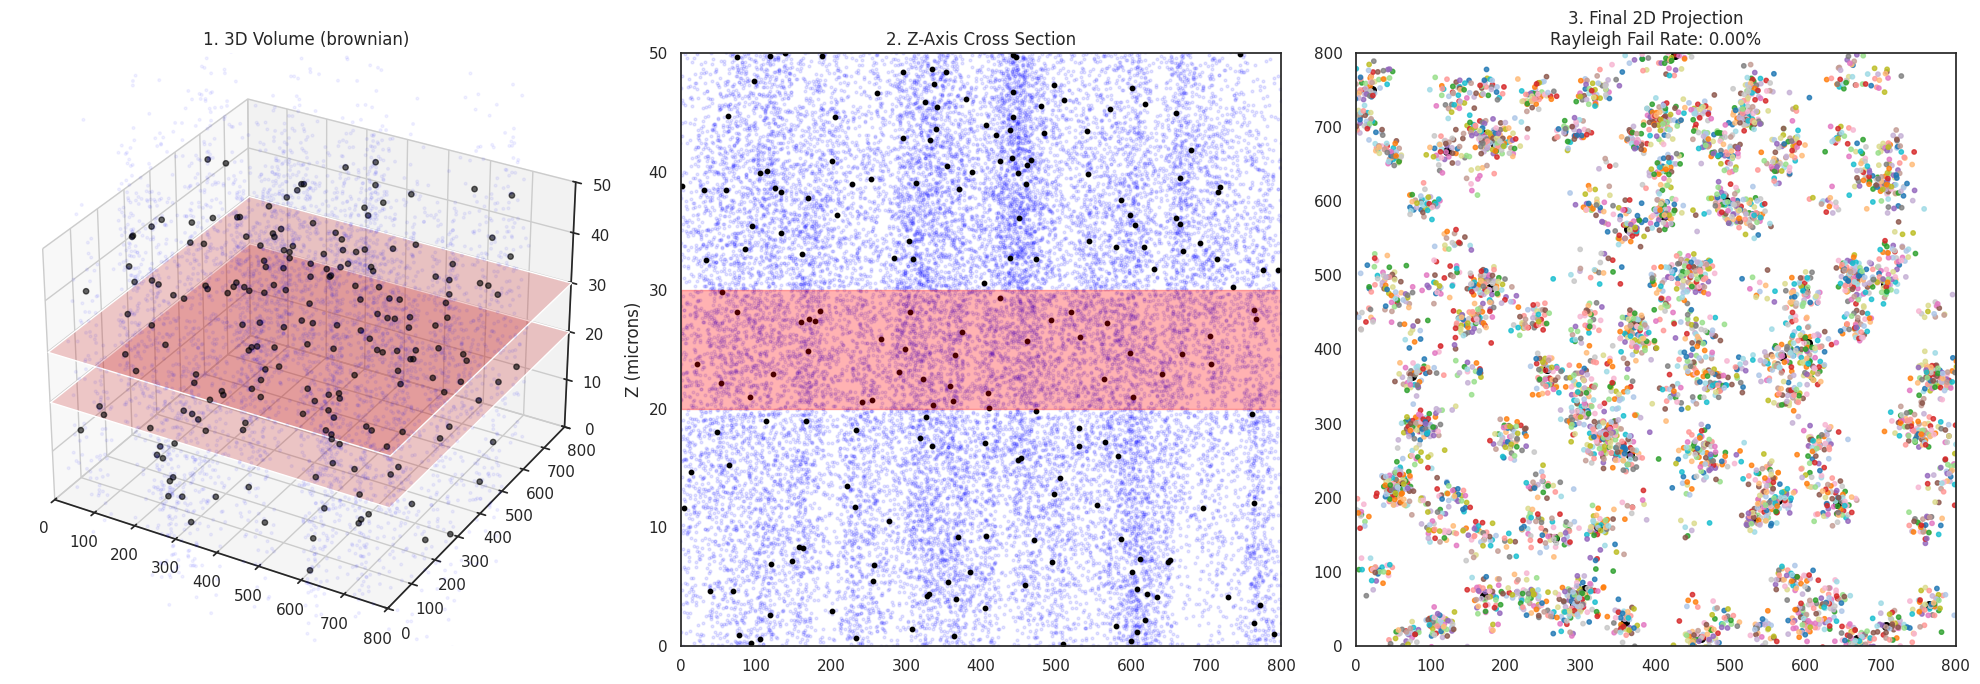

------------------------------
GLOBAL ASSESSMENT (All RNA in slice):
Proportion of genes fitting Rayleigh fit: 0.00%

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 100.00%
------------------------------

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 0.00%
------------------------------

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 95.00%
------------------------------


In [40]:
# 1. Define your parameters
space = (800, 800, 50) 
slice_thick = 10 

# 2. Run the simulation
# Note: The function now returns a dictionary when return_full=True
results_dict = run_diffusion_simulation_3d(
    n_cells=200,
    n_genes=20,
    mode='brownian',           # Try 'brownian' (3D) to see the difference!
    spatial_structure='random', 
    space_size=space,
    scale_diffusion=12,
    z_slice_thickness=slice_thick,
    exRNA_factor=0.4,          # 20% of RNA escapes
    plot=True,
    return_full=True,          # This triggers the dictionary return
    asessment_method='non-ratio',   # Using our new CV-based Ratio test
    save_path=saving_path/'example_brownian_spatial.pdf',
)

# 3. Inspect the results
print("-" * 30)
print(f"GLOBAL ASSESSMENT (All RNA in slice):")
print(f"Proportion of genes fitting Rayleigh fit: {results_dict['prop_global']:.2%}")

print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {results_dict['prop_in_plane']:.2%}")
print("-" * 30)

# 4. Deep dive into the In-Plane stats
stats_df = results_dict['stats_global']
prop_ad_significant_global=np.sum(stats_df['ad_is_significant']==False)/len(stats_df['ad_is_significant'])
print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {prop_ad_significant_global:.2%}")
print("-" * 30)

# 4. Deep dive into the In-Plane stats
stats_df = results_dict['stats_in_plane']
prop_ad_significant_in_plane=np.sum(stats_df['ad_is_significant']==False)/len(stats_df['ad_is_significant'])
print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {prop_ad_significant_in_plane:.2%}")
print("-" * 30)


Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...


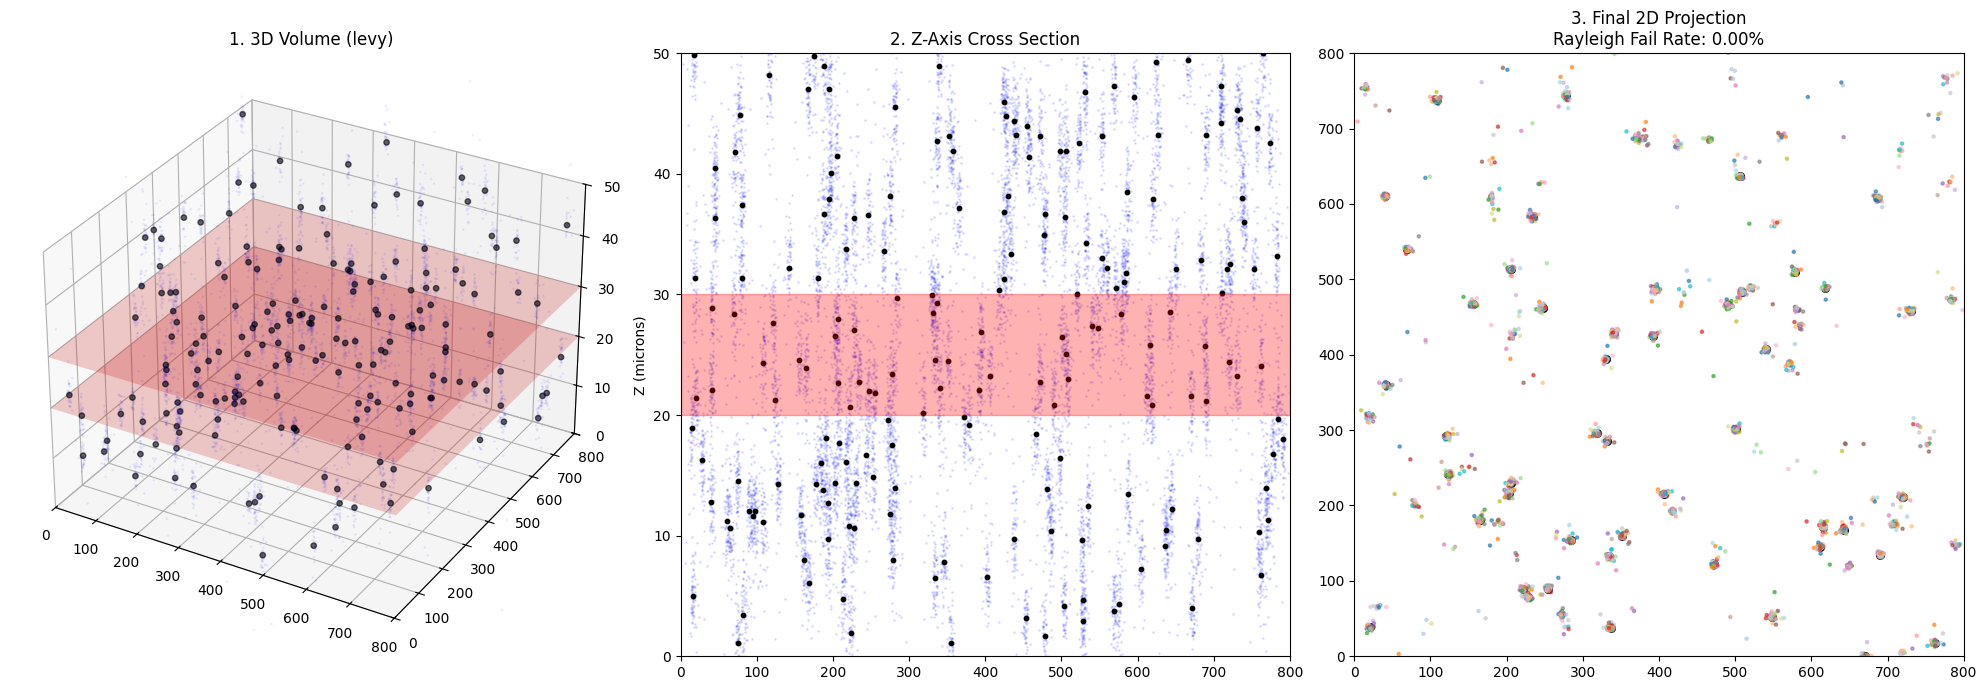

------------------------------
GLOBAL ASSESSMENT (All RNA in slice):
Proportion of genes fitting Rayleigh fit: 0.00%

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 0.00%
------------------------------

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 0.00%
------------------------------

IN-PLANE ASSESSMENT (RNA from visible cells only):
Proportion of genes fitting the Rayleigh fit: 0.00%
------------------------------


In [4]:
# 1. Define your parameters
space = (800, 800, 50) 
slice_thick = 10 

# 2. Run the simulation
# Note: The function now returns a dictionary when return_full=True
results_dict = run_diffusion_simulation_(
    n_cells=200,
    n_genes=20,
    mode='levy',           # Try 'brownian' (3D) to see the difference!
    spatial_structure='random', 
    space_size=space,
    scale_diffusion=2,
    z_slice_thickness=slice_thick,
    exRNA_factor=0.2,          # 20% of RNA escapes
    plot=True,
    return_full=True,          # This triggers the dictionary return
    asessment_method='non-ratio'   # Using our new CV-based Ratio test
)

# 3. Inspect the results
print("-" * 30)
print(f"GLOBAL ASSESSMENT (All RNA in slice):")
print(f"Proportion of genes fitting Rayleigh fit: {results_dict['prop_global']:.2%}")

print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {results_dict['prop_in_plane']:.2%}")
print("-" * 30)

# 4. Deep dive into the In-Plane stats
stats_df = results_dict['stats_global']
prop_ad_significant_global=np.sum(stats_df['ad_is_significant']==False)/len(stats_df['ad_is_significant'])
print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {prop_ad_significant_global:.2%}")
print("-" * 30)

# 4. Deep dive into the In-Plane stats
stats_df = results_dict['stats_in_plane']
prop_ad_significant_in_plane=np.sum(stats_df['ad_is_significant']==False)/len(stats_df['ad_is_significant'])
print("\nIN-PLANE ASSESSMENT (RNA from visible cells only):")
print(f"Proportion of genes fitting the Rayleigh fit: {prop_ad_significant_in_plane:.2%}")
print("-" * 30)


In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Define the experimental grid
modes = ['brownian', 'brownian_2d', 'levy', 'correlated', 'uniform']
scales = [1, 2,4,8,10, 15]
results = []

print("Starting Parameter Sweep: KS vs. AD Assessment...")

for m in modes:
    for s in scales:
        # Run the simulation
        results_dict = run_diffusion_simulation_3d(
            n_cells=500, 
            spatial_structure='clustered',
            n_genes=50, 
            space_size=(200, 200, 200),
            scale_diffusion=s, 
            z_slice_thickness=10,
            mode=m,
            exRNA_factor=0.5,
            plot=False, 
            return_full=True, 
            asessment_method='non_ratio' 
        )
        
        # Helper function to calculate AD pass rate (where ad_is_significant is False)
        def get_ad_pass_rate(df):
            if df is None or df.empty: return 0.0
            return np.sum(df['ad_is_significant'] == False) / len(df)

        # Extract Metrics
        # KS Pass Rates (already provided by your function)
        ks_global = results_dict['prop_global']
        ks_in_plane = results_dict['prop_in_plane']
        
        # AD Pass Rates (calculated from the full stats dataframes)
        ad_global = get_ad_pass_rate(results_dict.get('stats_global'))
        ad_in_plane = get_ad_pass_rate(results_dict.get('stats_in_plane'))
        
        print(f"Mode: {m:12} | Scale: {s:2} | KS Global: {ks_global:.1%} | AD Global: {ad_global:.1%}")
        
        results.append({
            'Movement_Mode': m,
            'Diffusion_Scale': s,
            'KS_Global': ks_global,
            'KS_In_Plane': ks_in_plane,
            'AD_Global': ad_global,
            'AD_In_Plane': ad_in_plane
        })

# 2. Convert to DataFrame
sweep_df = pd.DataFrame(results)

Starting Parameter Sweep: KS vs. AD Assessment...
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale:  1 | KS Global: 0.0% | AD Global: 0.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale:  2 | KS Global: 0.0% | AD Global: 0.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale:  4 | KS Global: 0.0% | AD Global: 0.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale:  8 | KS Global: 2.0% | AD Global: 0.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale: 10 | KS Global: 20.0% | AD Global: 6.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian     | Scale: 15 | KS Global: 0.0% | AD Global: 0.0%
Assessing Global Transcripts...
Assessing In-Plane Only Transcripts...
Mode: brownian_2d  | Scale:  1 | KS Global: 98.0% 

Publication figure safely saved to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/sisimulation_diffusion/diffusion_simulation_ks_comparison.pdf


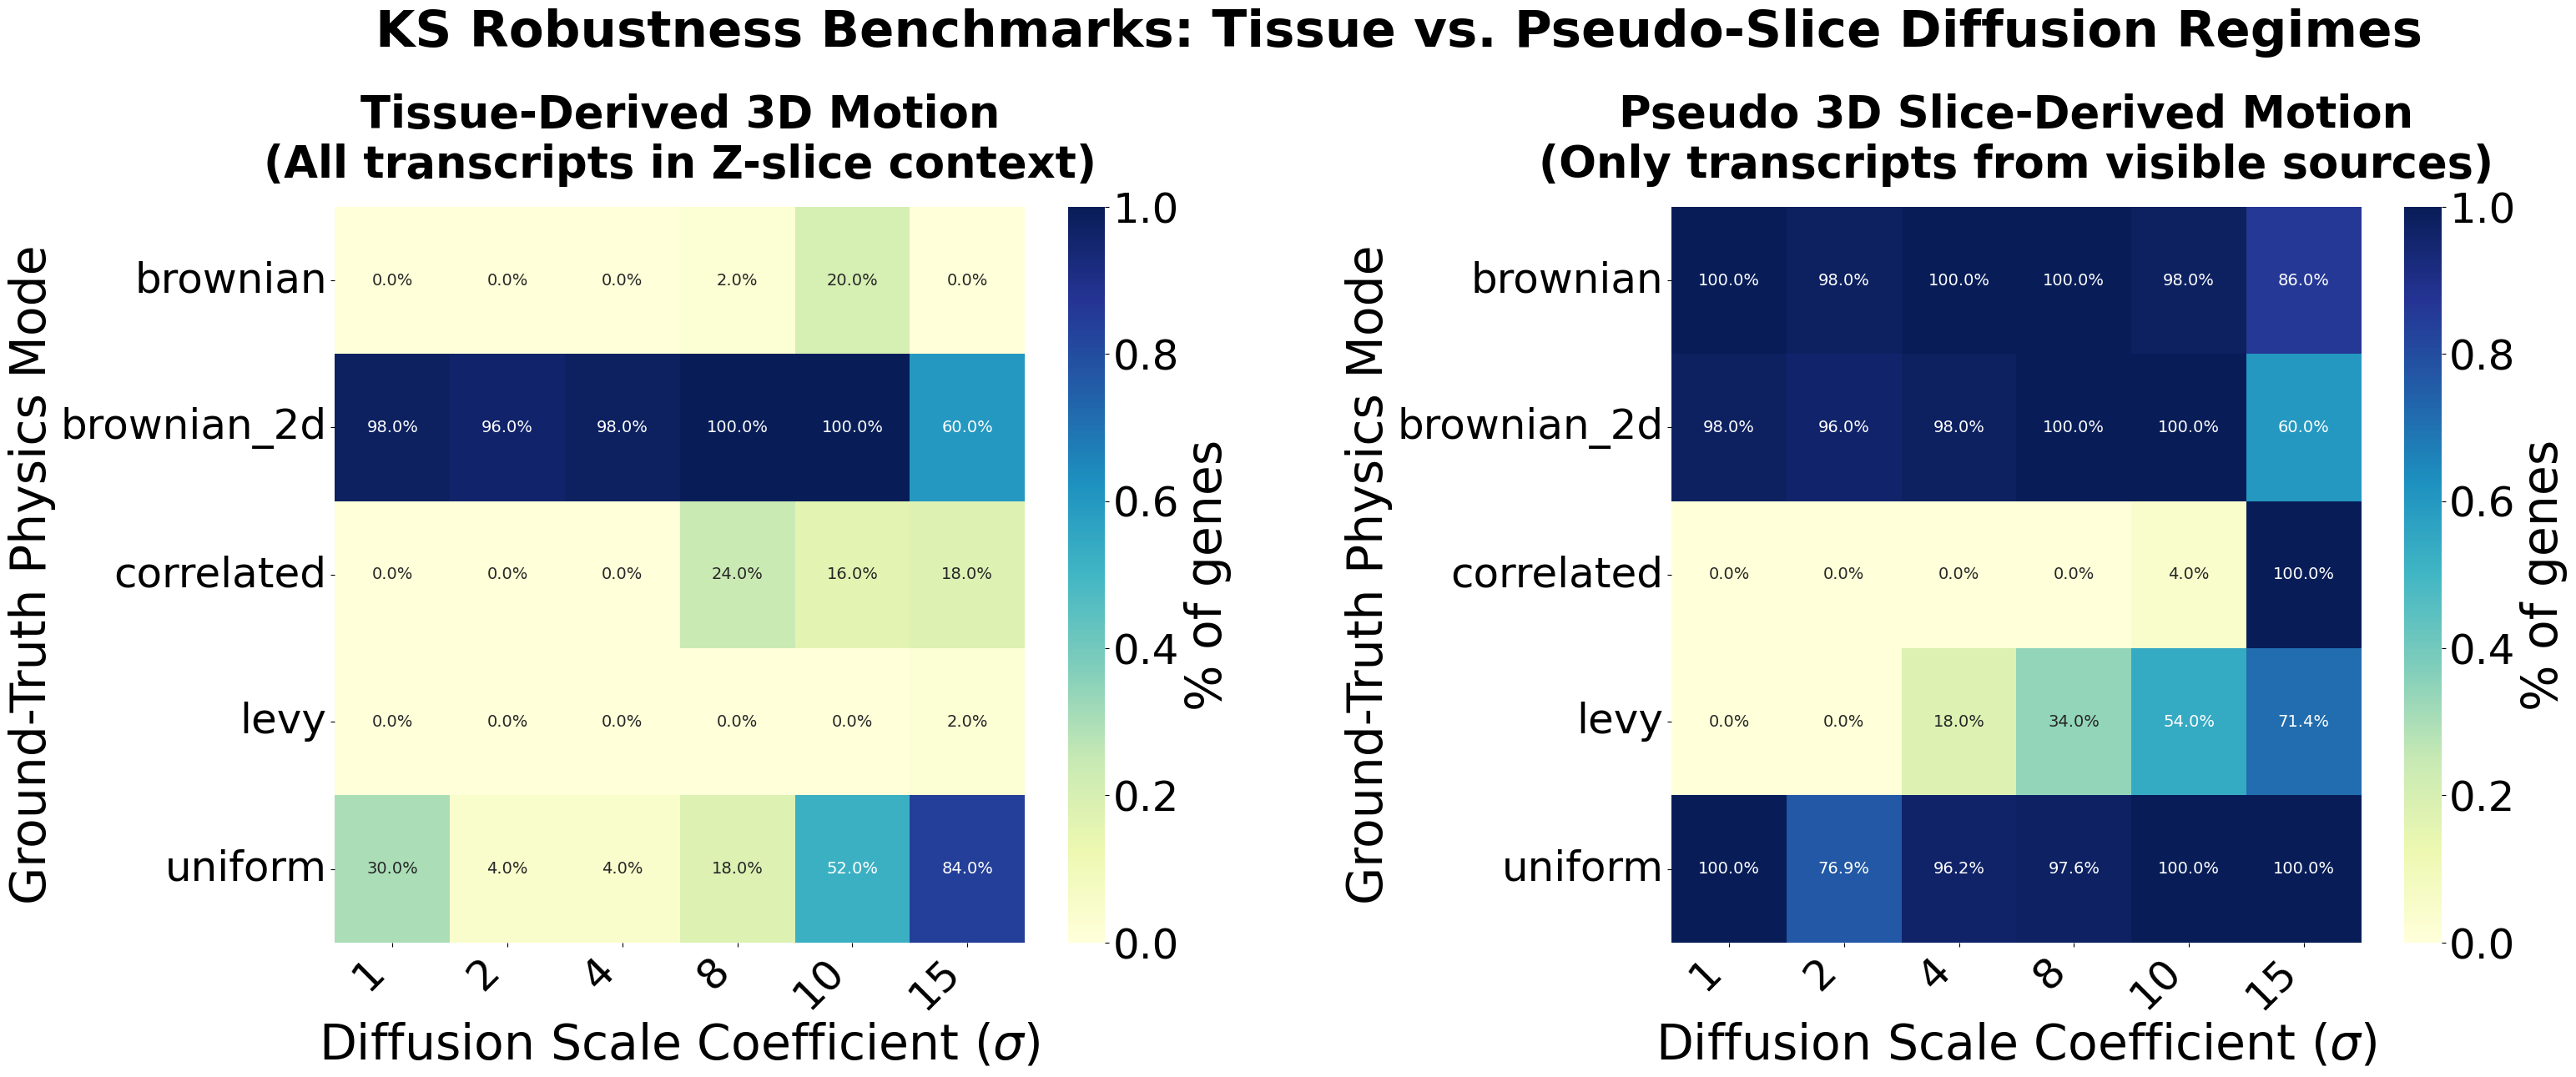

In [9]:
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Setup Path and Directories
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/sisimulation_diffusion")
saving_path.mkdir(parents=True, exist_ok=True)

# 2. Configure High-Resolution/Large-Font Publication Styles (For Axes and Labels)
plt.rcParams.update({
    'font.size': 42,
    'axes.labelsize': 42,
    'axes.titlesize': 38,       
    'xtick.labelsize': 36,
    'ytick.labelsize': 36,
    'figure.titlesize': 44
})

# User Parameters
cmap_choice = "YlGnBu"

# 3. Initialize Smaller, High-Density Figure Matrix
fig, axes = plt.subplots(1, 2, figsize=(34, 14))  # Expanded slightly to accommodate layout labels
plt.subplots_adjust(wspace=0.55, bottom=0.25)     

# 4. Define Configuration with your Nomenclature
plot_configs = [
    (
        "KS_Global", 
        "Tissue-Derived 3D Motion\n(All transcripts in Z-slice context)", 
        axes[0]
    ),
    (
        "KS_In_Plane", 
        "Pseudo 3D Slice-Derived Motion\n(Only transcripts from visible sources)", 
        axes[1]
    )
]

# 5. Generate Heatmaps
for col_name, title, ax in plot_configs:
    pivot = sweep_df.pivot(index="Movement_Mode", columns="Diffusion_Scale", values=col_name)
    
    # Render Heatmap Matrix
    sns.heatmap(
        pivot, 
        annot=True, 
        fmt=".1%", 
        cmap=cmap_choice, 
        ax=ax, 
        # FIX: Explicitly lock cell text sizing so it doesn't inherit the global 42pt
        annot_kws={"size": 14}, 
        cbar_kws={'label': '% of genes'}
    )
    
    # Structural Annotations
    ax.set_title(title, fontweight='bold', pad=25)
    ax.set_ylabel("Ground-Truth Physics Mode")
    ax.set_xlabel("Diffusion Scale Coefficient ($\sigma$)")
    
    # Tick Structural Rotations
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontweight='medium')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontweight='medium')

# 6. Global Figure Header
plt.suptitle(
    "KS Robustness Benchmarks: Tissue vs. Pseudo-Slice Diffusion Regimes", 
    fontweight='bold',
    y=1.05
)

# 7. Safe Export Pipeline (Using 'svg.fonttype': 'none' equivalent logic via pdf)
# Keeping text as vector fonts so you can click and change strings directly in Illustrator
output_file = saving_path / "diffusion_simulation_ks_comparison.pdf"
plt.savefig(output_file, format='pdf', bbox_inches='tight', dpi=300)
print(f"Publication figure safely saved to: {output_file}")

plt.show()

# Visualization of diffusion

Successfully generated and saved publication matrix to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/sisimulation_diffusion/rna_diffusion_grid.pdf


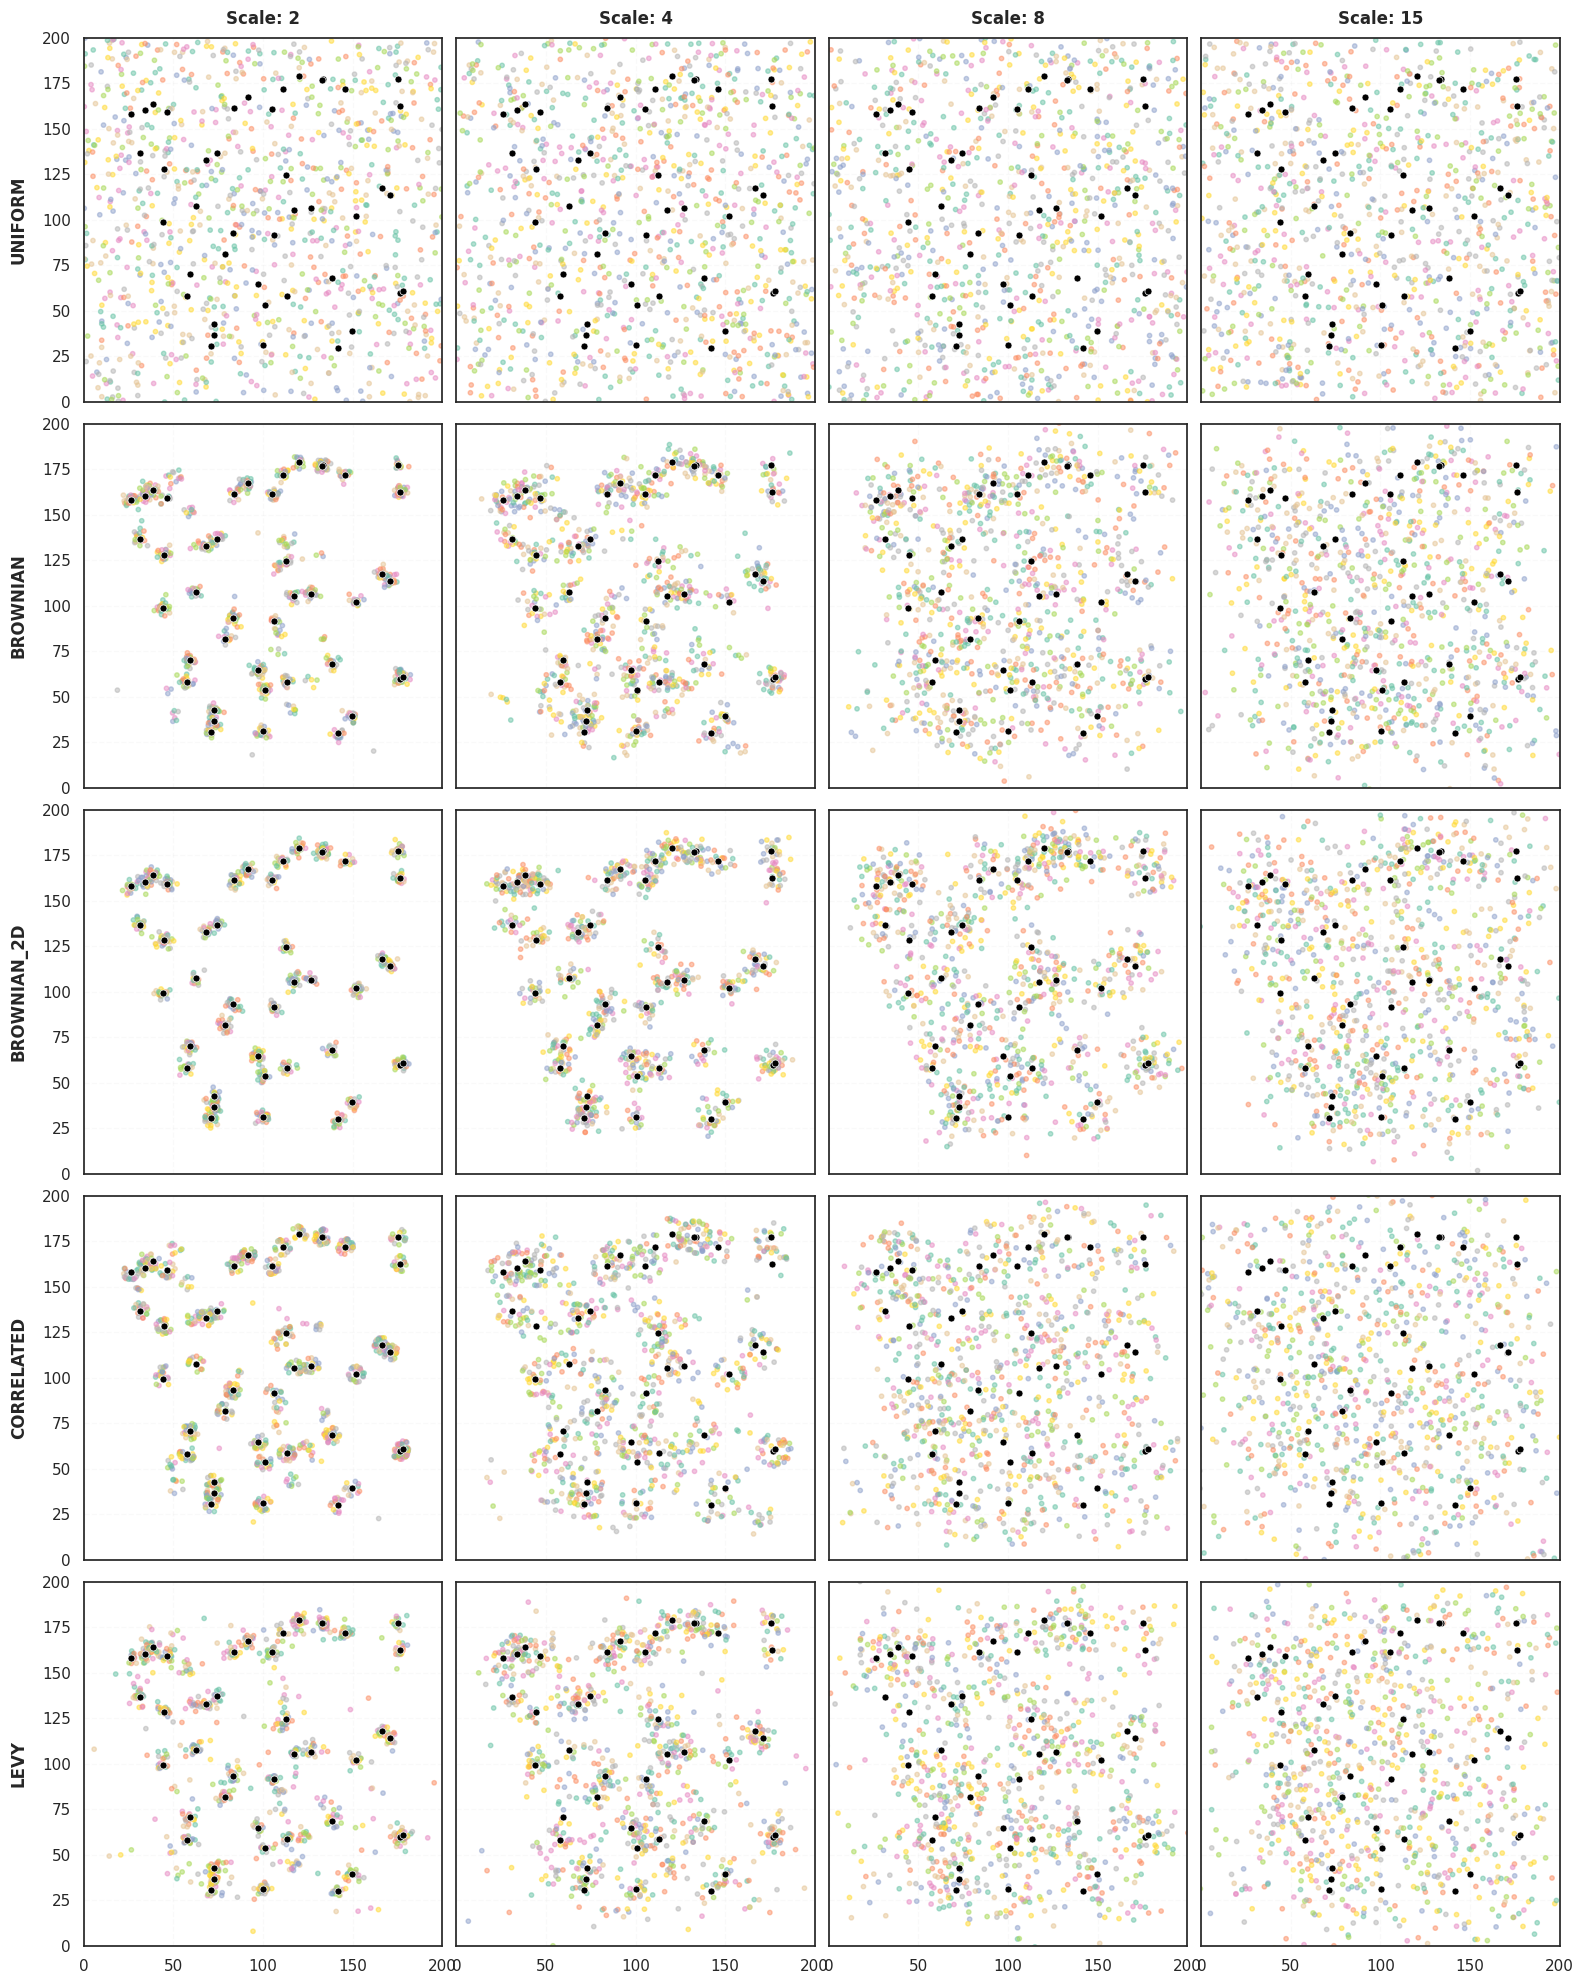

In [21]:
# =====================================================================
# 5. MULTI-CONFIGURATION MATRIX VISUALIZER (OPTIMIZED FOR PDF EXPORT)
# =====================================================================

def plot_diffusion_matrix(scales=[2, 4, 8, 15], 
                          modes=['uniform', 'brownian', 'brownian_2d', 'correlated', 'levy'],
                          n_cells=500, n_genes=50, space_size=(200, 200, 200),
                          z_slice_thickness=15, 
                          saving_path="diffusion_matrix.pdf"): # <--- Added path target
    """
    Generates a matrix of diffusion datasets, sections them optically along the Z-axis,
    and saves a tightly packed vector PDF of the resulting configurations.
    """
    nrows = len(modes)
    ncols = len(scales)
    width, height, depth = space_size
    
    z_center = depth / 2
    z_min = z_center - (z_slice_thickness / 2)
    z_max = z_center + (z_slice_thickness / 2)
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), 
                             sharex=True, sharey=True)
    
    pad_x, pad_y, pad_z = width * 0.1, height * 0.1, depth * 0.1
    base_cell_pos = np.random.uniform(
        low=[pad_x, pad_y, pad_z], 
        high=[width - pad_x, height - pad_y, depth - pad_z], 
        size=(n_cells, 3)
    )
    
    expression = np.random.poisson(lam=40, size=(n_cells, n_genes))
    genes = [f"Gene_{i}" for i in range(n_genes)]
    
    for row_idx, mode in enumerate(modes):
        for col_idx, scale in enumerate(scales):
            ax = axes[row_idx, col_idx]
            
            cells_df = pd.DataFrame(base_cell_pos, columns=["x", "y", "z"])
            cells_df["cell_id"] = [f"cell_{i}" for i in range(n_cells)]
            for i, gene in enumerate(genes): 
                cells_df[gene] = expression[:, i]
            
            exRNA_data = []
            
            for _, cell in cells_df.iterrows():
                cx, cy, cz = cell["x"], cell["y"], cell["z"]
                for gene in genes:
                    count = int(cell[gene] * 0.25)
                    if count <= 0: continue
                    
                    dx, dy, dz = get_displacement(count, scale, mode=mode, space_size=space_size, cell_pos=(cx, cy, cz))
                    
                    for x_off, y_off, z_off in zip(dx, dy, dz):
                        tx = (x_off if mode in ['uniform', 'uniform_2d'] else cx + x_off)
                        ty = (y_off if mode in ['uniform', 'uniform_2d'] else cy + y_off)
                        tz = (z_off if mode in ['uniform', 'uniform_2d'] else cz + z_off)
                        
                        exRNA_data.append({"x": tx, "y": ty, "z": tz, "gene": gene})
            
            exRNA_df = pd.DataFrame(exRNA_data)
            
            sliced_cells = cells_df[(cells_df["z"] >= z_min) & (cells_df["z"] <= z_max)]
            
            # --- Render Slices ---
            if not exRNA_df.empty:
                sliced_exRNA = exRNA_df[(exRNA_df["z"] >= z_min) & (exRNA_df["z"] <= z_max)]
                
                if not sliced_exRNA.empty:
                    samp_rna = sliced_exRNA.sample(min(len(sliced_exRNA), 1000))
                    gene_colors = pd.factorize(samp_rna["gene"])[0]
                    
                    # CHANGED: Updated to colormap Set2 and increased spot size by 50% (1.5 -> 2.25)
                    ax.scatter(samp_rna["x"], samp_rna["y"], c=gene_colors, cmap="Set2", s=10, alpha=0.5)
            
            if not sliced_cells.empty:
                # CHANGED: Increased cell spot anchor size by 50% (15 -> 22.5)
                ax.scatter(sliced_cells["x"], sliced_cells["y"], c="black", s=25.5, marker="o", edgecolors="white", linewidths=0.5)
            
            ax.set_xlim(0, width)
            ax.set_ylim(0, height)
            
            if row_idx == 0:
                ax.set_title(f"Scale: {scale}", fontsize=12, fontweight='bold', pad=10)
            if col_idx == 0:
                ax.set_ylabel(mode.upper(), fontsize=12, fontweight='bold', labelpad=10)
                
            ax.grid(True, linestyle="--", alpha=0.1)

    # --- Layout & Panel Spacing Adjustments ---
    plt.tight_layout()
    
    # CHANGED: Explicitly forces subpanels closer together horizontally and vertically
    fig.subplots_adjust(wspace=0.04, hspace=0.06)
    
    # --- PDF Export Action ---
    if saving_path:
        # bbox_inches='tight' prevents axis text or labels from being cropped off edges
        plt.savefig(saving_path, format='pdf', bbox_inches='tight', dpi=300)
        print(f"Successfully generated and saved publication matrix to: {saving_path}")

    plt.show()

# =====================================================================
# EXECUTION
# =====================================================================
plot_diffusion_matrix(saving_path=saving_path / "rna_diffusion_grid.pdf")


# Modify uRNA proportion

# Other

In [43]:
import os
import pandas as pd

# Base directory containing the different segmentation folders
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/"

# Define the segmentations you want to process
segmentations = ["rois", "rois_proseg"]

# Explicit column names for the final combined DataFrame
counts_keys = [
    "Intracellular", 
    "Cell-Like Connected",
    "Cell-Like Unconnected", 
    "High-Density Connected",
    "High-Density Unconnected", 
    "Noise Spectrum",
    "Iso. diffusion Compatible", 
    "Iso. diffusion Incompatible"
]

# Dictionary to hold the combined DataFrame for each segmentation
combined_segmentations_dict = {}

for seg in segmentations:
    print(f"\n--- Processing segmentation: {seg} ---")
    
    # Construct the root directory for the current segmentation
    root_dir = os.path.join(base_dir, seg)
    
    if not os.path.exists(root_dir):
        print(f"Directory not found: {root_dir}. Skipping...")
        continue

    # Initialize an empty list to hold individual metadata DataFrames for this segmentation
    metadata_list = []

    # List only first-level subdirectories
    subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

    for subfolder in subfolders:
        metadata_path = os.path.join(subfolder, "figures/transcript_categories.csv")
        
        if os.path.isfile(metadata_path):
            try:
                df = pd.read_csv(metadata_path)
                
                # Use the subfolder name as the temporary column header before transposing
                df.columns = [subfolder.split("/")[-1]]
                
                # Transpose so the subfolder name becomes the row index
                metadata_list.append(df.transpose())
            except Exception as e:
                print(f"Failed to read {metadata_path}: {e}")
                
    # Combine all metadata files into a single DataFrame for this segmentation
    if metadata_list:
        combined_summary = pd.concat(metadata_list, ignore_index=False)
        
        # Apply the explicit column names to the combined DataFrame
        if combined_summary.shape[1] == len(counts_keys):
            combined_summary.columns = counts_keys
        else:
            print(f"Warning: Column count mismatch for '{seg}'. "
                  f"Expected {len(counts_keys)}, got {combined_summary.shape[1]}. "
                  f"Columns were not renamed.")
        
        print(f"Combined metadata shape for '{seg}':", combined_summary.shape)
        
        # Store the resulting DataFrame in the dictionary
        combined_segmentations_dict[seg] = combined_summary
    else:
        print(f"No transcript_categories.csv files found for segmentation '{seg}'.")


--- Processing segmentation: rois ---
Combined metadata shape for 'rois': (17, 8)

--- Processing segmentation: rois_proseg ---
Combined metadata shape for 'rois_proseg': (17, 8)


In [ ]:
import itertools

# Define ranges of parameters
n_cells_list = [50, 100, 200,400]
scale_list = [5, 10, 20,50]
exrna_factors = [0.05, 0.1, 0.2]

# Generate all combinations of parameters
param_grid = list(itertools.product(n_cells_list, scale_list, exrna_factors))

# Store results
results = []

# Loop over parameter combinations
for n_cells, scale_rayleigh, exRNA_factor in param_grid:
    proportion = run_diffusion_simulation(
        n_cells=n_cells,
        scale_rayleigh=scale_rayleigh,
        exRNA_factor=exRNA_factor,
        return_full=False,plot=True  # Set to True if you want the full DataFrame
    )
    results.append({
        "n_cells": n_cells,
        "scale_rayleigh": scale_rayleigh,
        "exRNA_factor": exRNA_factor,
        "proportion_non_diffusive": proportion
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)
print(results_df)


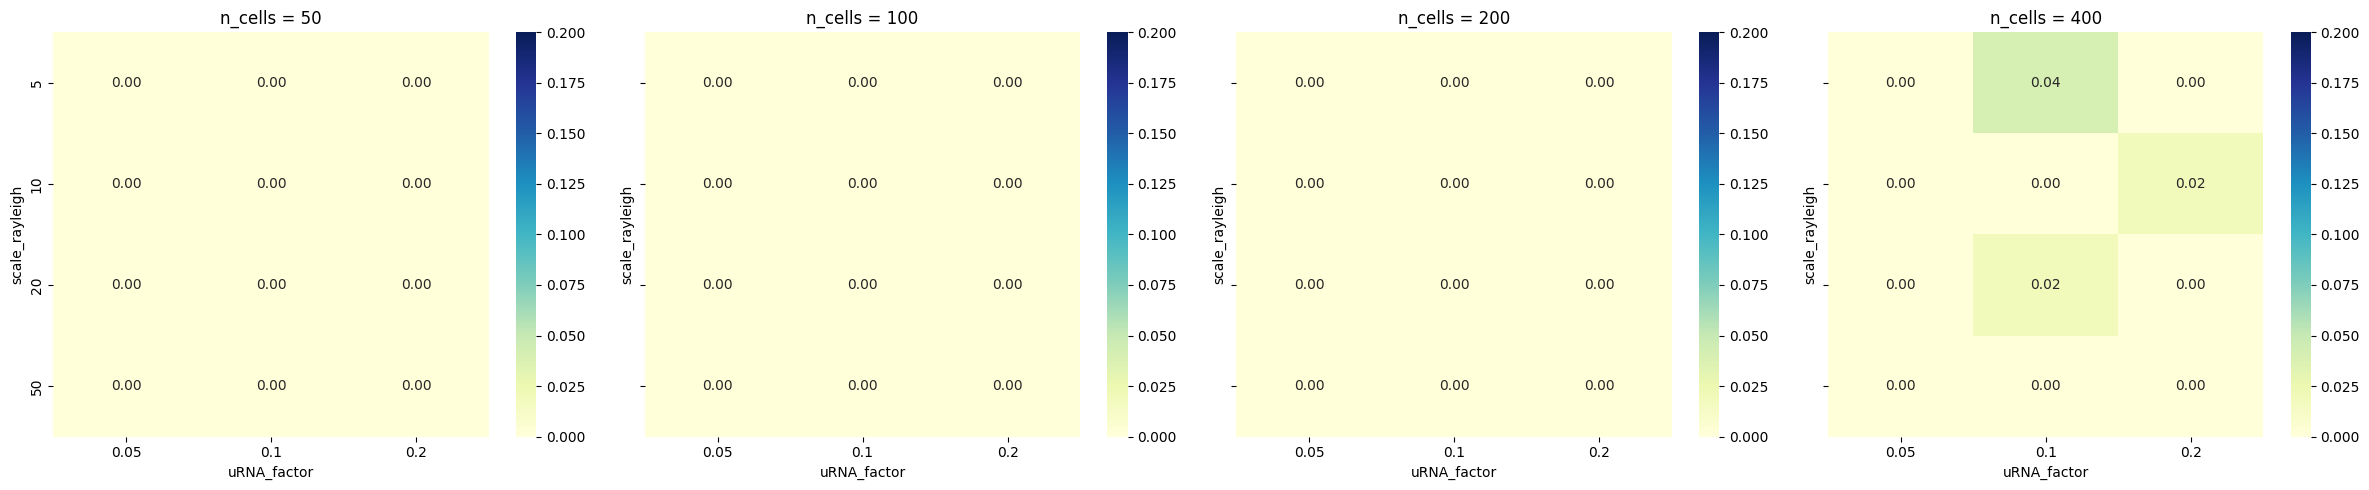

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

n_cells_values = sorted(results_df['n_cells'].unique())
n_subplots = len(n_cells_values)

fig, axes = plt.subplots(1, n_subplots, figsize=(6*n_subplots, 5), sharey=True)

# Determine global min and max for color scale
vmin = results_df['proportion_non_diffusive'].min()
vmax = 0.2

for ax, n_cells in zip(axes, n_cells_values):
    subset = results_df[results_df['n_cells'] == n_cells].pivot(
        index='scale_rayleigh', columns='exRNA_factor', values='proportion_non_diffusive'
    )
    sns.heatmap(subset, annot=True, fmt=".2f", cmap="YlGnBu",
                vmin=vmin, vmax=vmax, ax=ax)
    ax.set_title(f"n_cells = {n_cells}")
    ax.set_xlabel("uRNA_factor")
    ax.set_ylabel("scale_rayleigh")

plt.tight_layout()


plt.show()
